Rebaabetswe Kotu
ST10547119

A medical aid company has a concern over negative reviews they have been receiving on a consumer review platform. Out of concern for their reputation, the company wants to understand their client's main areas of concern and to have a general sentiment of how their clients are experiencing their services. The company has requested a text analysis on the reviews so they can identify the concerns and get an idea of client's sentiments. A dataset with 400 reviews was used in this project, however, the dataset is synthetic, AI generated. The reviews do not represent those of actual clients. This project aims to demonstrate how Natural language processing and machine learning can be used to assess consumer sentiments and identify their concerns.

In [37]:
#Importing libraries

from pathlib import Path
import re, json, warnings
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from sklearn.feature_extraction.text import CountVectorizer, TfidfVectorizer, ENGLISH_STOP_WORDS
from sklearn.decomposition import LatentDirichletAllocation
from sklearn.model_selection import train_test_split, GridSearchCV, StratifiedKFold
from sklearn.pipeline import Pipeline
from sklearn.linear_model import LogisticRegression
from sklearn.naive_bayes import MultinomialNB
from sklearn.metrics import (accuracy_score, precision_recall_fscore_support,
                             classification_report, ConfusionMatrixDisplay, confusion_matrix)
from wordcloud import WordCloud
warnings.filterwarnings('ignore', category=FutureWarning)
SEED=42
np.random.seed(SEED)


Exploratory data analysis, processing and data engineering

The dataset is inspected for column types, duplicates, missing values, shape and class balance.

In [38]:
#Loading the dataset
df = pd.read_csv("medical_aid_customer_reviews_revised.csv")
display(df.head(10))

,ReviewID,ReviewDate,ReviewText,Sentiment,TopicSeed,SyntheticData
0,1,11/06/2022 09:00,I want to share my experience with the medical...,Positive,Claims processing,Yes
1,2,29/10/2024 10:31,I have been reviewing how my medical aid handl...,Positive,Membership and dependants,Yes
2,3,21/06/2024 20:32,I am sharing feedback following my latest inte...,Neutral,Dental and optical benefits,Yes
3,4,30/06/2024 11:08,I recently needed assistance with a healthcare...,Positive,Customer service,Yes
4,5,05/03/2022 04:16,I want to share my experience with the medical...,Negative,Premiums and contributions,Yes
5,6,29/10/2023 17:23,This is feedback about a recent interaction wi...,Positive,Hospital authorisation,Yes
6,7,19/03/2022 22:49,I have been reviewing how my medical aid handl...,Negative,Claims processing,Yes
7,8,25/02/2025 05:10,My experience this month involved an issue wit...,Positive,Benefit limits and exclusions,Yes
8,9,25/03/2023 13:35,I recently needed assistance with a healthcare...,Negative,Membership and dependants,Yes
9,10,05/03/2022 08:32,This is feedback about a recent interaction wi...,Negative,Customer service,Yes


In [39]:

print('Shape:',raw.shape); display(raw.dtypes.rename('dtype').to_frame())
print('Missing by column:'); display (raw.isna().sum().to_frame('missing'))
print('Duplicate ReviewText:',raw['ReviewText'].duplicated().sum())
print('Synthetic indicator:'); display(raw['SyntheticData'].value_counts(dropna=False))
print('Sentiment:'); display(raw['Sentiment'].value_counts().to_frame('n'))
print('TopicSeed counts (generation metadata; not modelling input):'); display(raw['TopicSeed'].value_counts().to_frame('n'))

Shape: (400, 6)


,dtype
ReviewID,int64
ReviewDate,str
ReviewText,str
Sentiment,str
TopicSeed,str
SyntheticData,str


Missing by column:


,missing
ReviewID,0
ReviewDate,0
ReviewText,0
Sentiment,0
TopicSeed,0
SyntheticData,0


Duplicate ReviewText: 0
Synthetic indicator:


SyntheticData
Yes    400
Name: count, dtype: int64

Sentiment:


,n
Sentiment,
Positive,215
Negative,138
Neutral,47


TopicSeed counts (generation metadata; not modelling input):


,n
TopicSeed,
Claims processing,41
Membership and dependants,41
Dental and optical benefits,40
Customer service,40
Premiums and contributions,40
Hospital authorisation,40
Benefit limits and exclusions,40
Chronic medication,40
Provider network and co-payments,39


The AI generated dataset is made up of 400 rows and 6 columns. There are no missing values or duplicates. The sentiment column is split into 3 categories, positive, negative and neutral. 215 records are positive, 138 are negative and 47 are neutral. TopicSeed variable was used to categorise reviews according to various services offered by the medical aid company. However, it was not included in machine learning input features.

In [40]:
#Text cleaning

def clean_text(text):
    text=re.sub(r'\[[^]]*\]',' ',str(text))
    text=re.sub(r'https?://\s+',' ',text)
    text=re.sub(r'\s+',' ',text)
    return text.strip()

data=raw[['ReviewText','Sentiment']].dropna().copy()
data['ReviewText']=data['ReviewText'].astype(str)
data['Sentiment']=data['Sentiment'].astype(str).str.strip().str.title()
data=data[data['Sentiment'].isin(['Negative', 'Neutral', 'Positive'])].copy()
data['CleanText']=data['ReviewText'].map(clean_text)
data=data[data['CleanText'].str.len()>0].drop_duplicates(subset=['CleanText']).reset_index(drop=True)
data['WordCount']=data['CleanText'].str.split().str.len()
print('Retained:',len(data),'rows')
for idx in range(2):
    print('\nBEFORE:',data.loc[idx,'ReviewText'][:240])
    print('AFTER: ',data.loc[idx,'CleanText'][:240])
print('Review length summary:');display(data.groupby('Sentiment')['WordCount'].describe().round(1))

Retained: 400 rows

BEFORE: I want to share my experience with the medical aid provider. I submitted a claim for a specialist consultation after my appointment. The claim appeared on my statement within three working days. The benefit payment matched the amount shown 
AFTER:  I want to share my experience with the medical aid provider. I submitted a claim for a specialist consultation after my appointment. The claim appeared on my statement within three working days. The benefit payment matched the amount shown 

BEFORE: I have been reviewing how my medical aid handled a recent request. I requested a correction to my dependant’s surname. The team verified the documents and updated the record promptly. The new membership details were accurate. I was dealing 
AFTER:  I have been reviewing how my medical aid handled a recent request. I requested a correction to my dependant’s surname. The team verified the documents and updated the record promptly. The new membership details were accurate

,count,mean,std,min,25%,50%,75%,max
Sentiment,,,,,,,,
Negative,138.0,67.7,4.3,56.0,65.0,68.0,70.0,79.0
Neutral,47.0,67.0,4.0,59.0,64.0,67.0,70.0,76.0
Positive,215.0,64.5,4.2,49.0,61.5,64.0,67.0,76.0


Text cleaning is performed on the dataset as an important part of data processing, the process ensures to keep the text standard, removes unncessary stop words and irrelevant characters to retain meaningful information that could contribute to sentiment classification and topic modelling. *Text data that is not cleaned has a risk of introducing noise into the dataset. The irrelevant text may affect feature extraction and reduce interpretability of results.

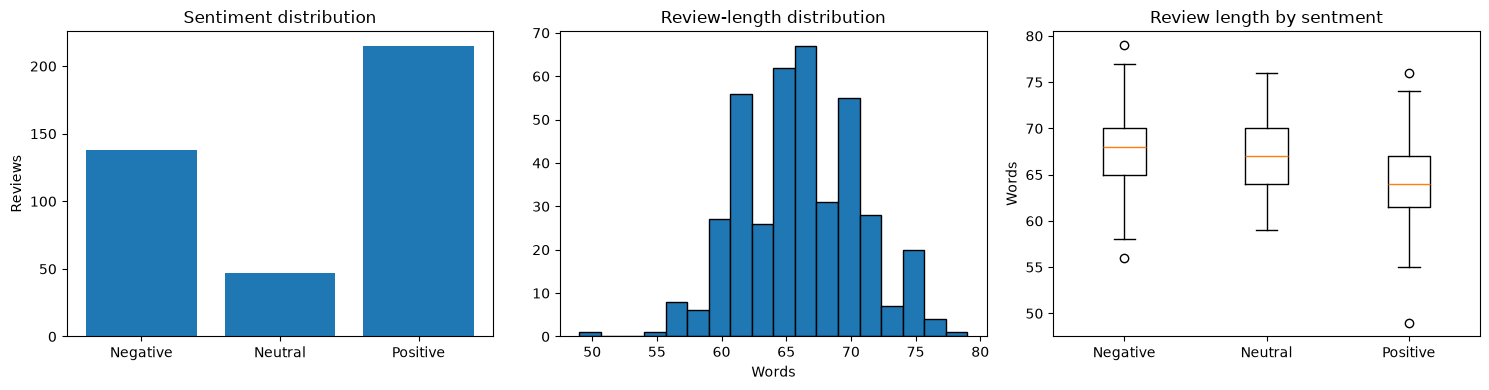

In [41]:
#Distribution visualisations

fig,axes=plt.subplots(1,3,figsize=(15,4))
counts=data['Sentiment'].value_counts().reindex(['Negative','Neutral','Positive'])
axes[0].bar(counts.index,counts.values);axes[0].set_title('Sentiment distribution');axes[0].set_ylabel('Reviews')
axes[1].hist(data['WordCount'],bins=18,edgecolor='black');axes[1].set_title('Review-length distribution');axes[1].set_xlabel('Words')
axes[2].boxplot([data.loc[data.Sentiment==s,'WordCount'] for s in counts.index],tick_labels=list(counts.index));axes[2].set_title('Review length by sentment');axes[2].set_ylabel('Words')
plt.tight_layout();plt.savefig(OUT/'01_eda_distributions.png',dpi=160);plt.show()

The above demonstrate the distribution of sentiments and review's length.

-The sentiment distribution bar demonstrates that there are just over 200 positive sentiments, followed by negative sentiments which a re just below 150, and lastly, neutral reviews which are just below 50.
-The review length distribution demonstrate various lengths of review sentences, some reviews are brief and therefore short sentences, while the detailed reviews have long sentences. Most reviews are about 60 to 71 words long, this indicates that most reviews are moderately detailed. The longest reviews have about 79 words, while the shortest have about 49 words.
-The boxplot demonstrate that negative reviews have a slightly higher word count at about 68 words, followed closely by neutral reviews with about 67 words, and lastly positive reviews at about 64 words.

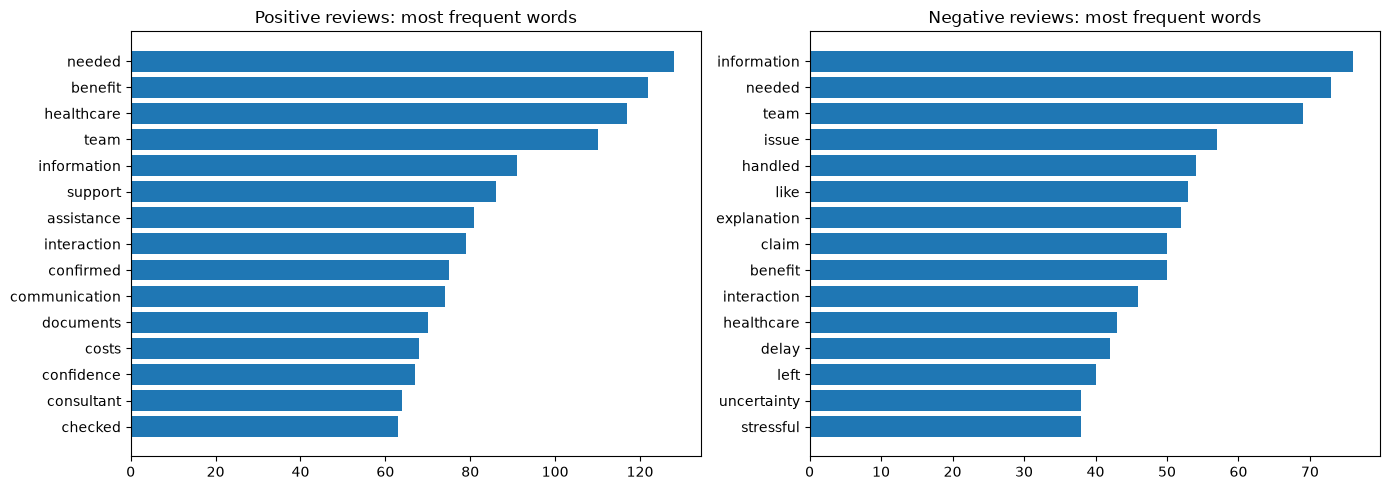

Positive words: [('needed', 128), ('benefit', 122), ('healthcare', 117), ('team', 110), ('information', 91), ('support', 86), ('assistance', 81), ('interaction', 79), ('confirmed', 75), ('communication', 74)]
Negative words: [('information', 76), ('needed', 73), ('team', 69), ('issue', 57), ('handled', 54), ('like', 53), ('explanation', 52), ('claim', 50), ('benefit', 50), ('interaction', 46)]


In [42]:
#Word frequencies

GENERIC={'medical','aid','scheme','provider','company','members','review','experience','overall','recent','recent',
         'request', 'asked', 'wanted', 'felt', 'share', 'sharing', 'latest', 'interactions', 'blue'}
EDA_STOP=set(ENGLISH_STOP_WORDS)|GENERIC

def word_counts(texts,n=15):
    tokens=[]
    for text in texts:
        tokens.extend([w for w in re.findall(r'\b[a-z]{3,}\b',text.lower()) if w not in EDA_STOP])
    return Counter(tokens).most_common(n)

fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,s in zip(axes,['Positive','Negative']):
    terms=word_counts(data.loc[data.Sentiment==s,'CleanText'])
    ax.barh([x[0] for x in terms][::-1],[x[1] for x in terms][::-1]);ax.set_title(s+' reviews: most frequent words')
plt.tight_layout();plt.savefig(OUT/'02_word_frequencies.png',dpi=160);plt.show()
print('Positive words:',word_counts(data.loc[data.Sentiment=='Positive','CleanText'],10))
print('Negative words:',word_counts(data.loc[data.Sentiment=='Negative','CleanText'],10))

Identifying words that appear the most in reviews assists in noting recurring subjects as well as satisfaction and dissatisfaction. The above distributions demonstrate frequencies of words in both the positive and negative reviews. In the positive reviews, the most reccuring word is needed, appearing 128 times and the least used word is checked appearing about 63 times. The most frequently used word in the negative reviews is information appearing 76 times and the least used is stressful, appearing about 38 times. Word frequency analysis is exploratory, therefore further analysis is required to identify underlying themes.

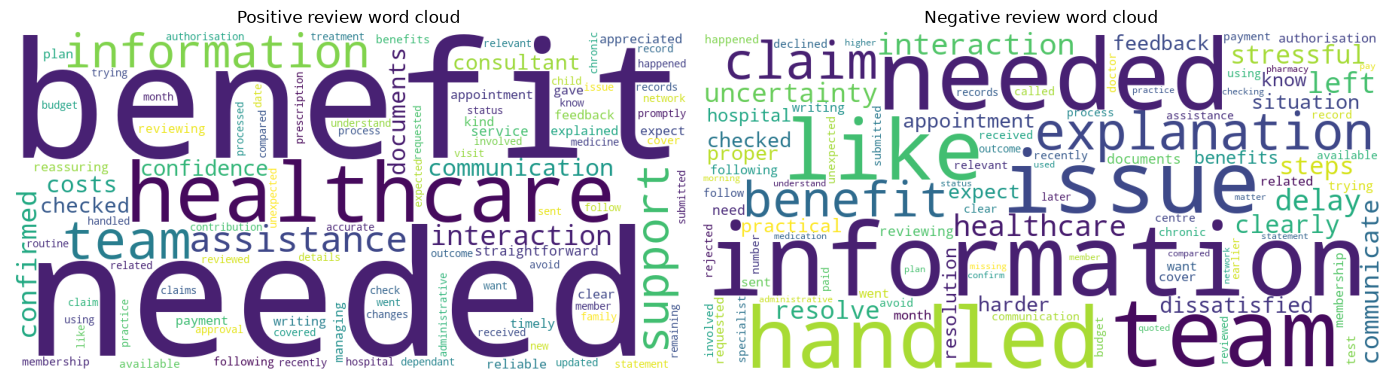

In [43]:
#Word clouds

fig,axes=plt.subplots(1,2,figsize=(14,5))
for ax,s in zip(axes,['Positive','Negative']):
    words=Counter(dict(word_counts(data.loc[data.Sentiment==s,'CleanText'],100)))
    cloud=WordCloud(width=900,height=450,background_color='white',random_state=SEED).generate_from_frequencies(words)
    ax.imshow(cloud);ax.axis('off');ax.set_title(s+' review word cloud')
plt.tight_layout();plt.savefig(OUT/'03_word_clouds.png',dpi=160);plt.show()

An analysis of the word clouds was done separetely, one for negative reviews, and the other for positive reviews. With word clouds, we are able to identify most frequently used words in each sentiment category, what customer feedback commonly entails, potential area of dissatisfaction and satisfaction and it also supports word-frequecy bar charts findings.

In [ ]:
Unsupervised topic modelling: Latent Dirichlet Allocation

Negative-review document-term matrix: (138, 992)


,topics,perplexity
0,3,683.582629
1,4,661.049883
2,5,658.624470
3,6,662.793468


Topic (i+1): healthcare,want,higher,network,communicate,clearly,like resolve,steps,resolve,resolve communicate,steps clearly,communicate steps
 Representative negative review: I recently needed assistance with a healthcare-related benefit. My monthly contribution increased at renewal. The notice arrived after I had already planned my household budget. I want earlier communication and a clearer reason for the increase. I needed an answer before making a
Topic (i+1): needed,healthcare,benefit,uncertainty stressful,uncertainty,stressful,like,hospital,benefits,delay,communicate steps,clearly
 Representative negative review: I recently needed assistance with a healthcare-related benefit. I went for an eye test believing I still had optical benefits. The optometrist was told the limit had already been used. I could not find a clear record of the earlier deductions. I had to coordinate the matter with 
Topic (i+1): explanation,handled,issue,practical,proper explanation,proper,expect,expect pr

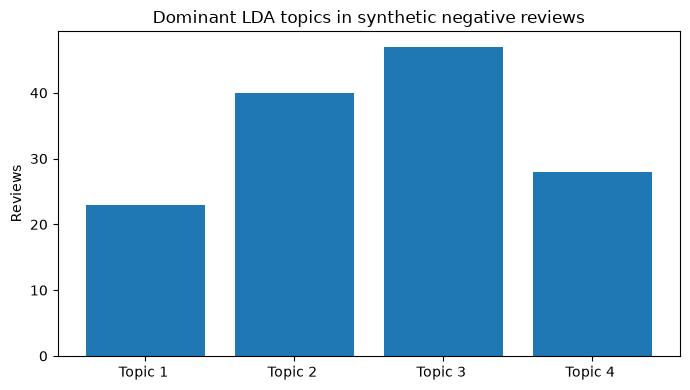

Caution: these topic counts are exploratory and depend on K and synthetic phrasing.


In [44]:
TOPIC_STOP=sorted(set(ENGLISH_STOP_WORDS)|GENERIC|{'time','times','working', 'days', 'really', 'quite', 'just',
                                                   'said', 'need', 'make', 'sure', 'information', 'details', 'plan', 'plans', 'service',
                                                   'services', 'team', 'customer', 'customers'})
negative_text=data.loc[data.Sentiment=='Negative', 'CleanText'].tolist()
cv=CountVectorizer(stop_words=TOPIC_STOP,ngram_range=(1,2),min_df=2,max_df=.90,max_features=1400)
X_topic=cv.fit_transform(negative_text)
terms=np.array(cv.get_feature_names_out())
print('Negative-review document-term matrix:',X_topic.shape)

topic_trials=[]
for k in [3,4,5,6]:
    candidate=LatentDirichletAllocation(n_components=k,random_state=SEED,max_iter=25,learning_method='batch')
    candidate.fit(X_topic)
    topic_trials.append({'topics':k,'perplexity':candidate.perplexity(X_topic)})
display(pd.DataFrame(topic_trials))

#4 themes to interpret
k=4
lda=LatentDirichletAllocation(n_components=k,random_state=SEED,max_iter=25,learning_method='batch')
probs=lda.fit_transform(X_topic)
for i,weights in enumerate(lda.components_):
    top=terms[np.argsort(weights)[-12:][::-1]]
    print(f'Topic (i+1):',','.join(top))
    ix=int(np.argmax(probs[:,i]));print(' Representative negative review:',negative_text[ix][:280])
assigned=probs.argmax(axis=1)
fig,ax=plt.subplots(figsize=(7,4));ax.bar([f'Topic {i+1} 'for i in range(k)],np.bincount(assigned,minlength=k))
ax.set_title('Dominant LDA topics in synthetic negative reviews');ax.set_ylabel('Reviews')
plt.tight_layout();plt.savefig(OUT/'04_lda_topic_distribution.png',dpi=160);plt.show()
print('Caution: these topic counts are exploratory and depend on K and synthetic phrasing.')

The medical aid company's concern is based mainly on the negative reviews. LDA was therefore only applied to the negative reviews. From 138 negative reviews, the model identified 4 topics for interpretation. Topic 1 relates to service resolution and explanations, topic 2 is about claims processing and communication, the 3rd topic relates to medical aid coverage and unresolved issues, and the 4th topic is about delays, uncertainity and customer stress. The distribution of the topics demonstrate which topic is more prevalent than the others, this is important because the company will be able to identify where most of the dissatisfaction is coming from. The bar graph does show that topic 3, medical aid and resolved issues accounts for most of the negative reviews, while topic 1, service resolution and explanations is the least discussed topic.

Sentiment feature engineering and train-test split

In [45]:
X_train,X_test,y_train,y_test=train_test_split(data['CleanText'],data['Sentiment'],test_size=.20,random_state=SEED,stratify=data['Sentiment'])
print('Train:',len(X_train),'Test:',len(X_test));display(pd.DataFrame({'train':y_train.value_counts(),'test':y_test.value_counts()}))

def lr_pipeline():
    return Pipeline([('tfidf',TfidfVectorizer(lowercase=True,strip_accents='unicode',sublinear_tf=True,max_df=.98)),
                     ('model',LogisticRegression(max_iter=2000,solver='lbfgs',random_state=SEED))])

def nb_pipeline():
    return Pipeline([('tfidf',TfidfVectorizer(lowercase=True,strip_accents='unicode',sublinear_tf=True,max_df=.98)),
                     ('model',MultinomialNB())])
base_lr=lr_pipeline().fit(X_train,y_train)
base_nb=nb_pipeline().fit(X_train,y_train)
print('Baseline models fitted on training data only.')

Train: 320 Test: 80


,train,test
Sentiment,,
Positive,172,43
Negative,110,28
Neutral,38,9


Baseline models fitted on training data only.


The dataset is split into 80% training set and 20% testing set. The 80% is accounted for by 320 reviews from the 400, while the 20% is accounted for by the remaining 80 reviews. The 80% training set is used to develop multinomial Naive Bayes and logistic regression models, while the testing set is used to evaluate how accurately the model can classify previously unseen reviews. The input feature (X) is the CleanText column and the target variable is the Sentiment column. Due to uneven distribution of negative, positive and neutral reviews in both datasets, we applied stratified sampling to try and balance the distribution of each sentiment category in both datasets.

Evaluation and improvement

In [47]:
cv=StratifiedKFold(n_splits=5,shuffle=True,random_state=SEED)
common={'tfidf__ngram_range':[(1,1),(1,2)],'tfidf__min_df':[1,2]}
lr_params={**common,'model__C':[0.1,1,10],'model__class_weight':[None,'balanced']}
nb_param={**common,'model__alpha':[0.1,0.5,1.0]}
lr_search=GridSearchCV(lr_pipeline(),lr_params,scoring='f1_macro',cv=cv,n_jobs=1,refit=True)
nb_search=GridSearchCV(nb_pipeline(),nb_param,scoring='f1_macro',cv=cv,n_jobs=1,refit=True)
lr_search.fit(X_train,y_train);nb_search.fit(X_train,y_train)
print('LR best:',lr_search.best_params_,'CV macro F1:',round(lr_search.best_score_,4))
print('NB best:',nb_search.best_params_,'CV macro F1:',round(nb_search.best_score_,4))
print('Top LR CV candidates:');display(pd.DataFrame(lr_search.cv_results_).sort_values('rank_test_score')[['params','mean_test_score',
                                                                                                           'std_test_score']].head(6))
print('Top NB CV candidates:');display(pd.DataFrame(nb_search.cv_results_).sort_values('rank_test_score')[['params','mean_test_score',
                                                                                                           'std_test_score']].head(6))


LR best: {'model__C': 0.1, 'model__class_weight': 'balanced', 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)} CV macro F1: 1.0
NB best: {'model__alpha': 0.1, 'tfidf__min_df': 1, 'tfidf__ngram_range': (1, 1)} CV macro F1: 1.0
Top LR CV candidates:


,params,mean_test_score,std_test_score
7,"{'model__C': 0.1, 'model__class_weight': 'bala...",1.0,0.0
6,"{'model__C': 0.1, 'model__class_weight': 'bala...",1.0,0.0
5,"{'model__C': 0.1, 'model__class_weight': 'bala...",1.0,0.0
4,"{'model__C': 0.1, 'model__class_weight': 'bala...",1.0,0.0
12,"{'model__C': 1, 'model__class_weight': 'balanc...",1.0,0.0
13,"{'model__C': 1, 'model__class_weight': 'balanc...",1.0,0.0


Top NB CV candidates:


,params,mean_test_score,std_test_score
0,"{'model__alpha': 0.1, 'tfidf__min_df': 1, 'tfi...",1.000000,0.000000
1,"{'model__alpha': 0.1, 'tfidf__min_df': 1, 'tfi...",1.000000,0.000000
2,"{'model__alpha': 0.1, 'tfidf__min_df': 2, 'tfi...",1.000000,0.000000
3,"{'model__alpha': 0.1, 'tfidf__min_df': 2, 'tfi...",1.000000,0.000000
6,"{'model__alpha': 0.5, 'tfidf__min_df': 2, 'tfi...",0.988522,0.014096
4,"{'model__alpha': 0.5, 'tfidf__min_df': 1, 'tfi...",0.969236,0.034277


,Model,Accuracy,Macro precision,Macro recall,Macro F1,Weighted F1
1,LR tuned,1.0000,1.0000,1.0000,1.0000,1.0000
3,NB tuned,1.0000,1.0000,1.0000,1.0000,1.0000
0,LR baseline,0.9875,0.9885,0.9630,0.9745,0.9872
2,NB baseline,0.9625,0.9737,0.8889,0.9199,0.9591



 LR baseline 
               precision    recall  f1-score   support

    Negative       0.97      1.00      0.98        28
     Neutral       1.00      0.89      0.94         9
    Positive       1.00      1.00      1.00        43

    accuracy                           0.99        80
   macro avg       0.99      0.96      0.97        80
weighted avg       0.99      0.99      0.99        80


 LR tuned 
               precision    recall  f1-score   support

    Negative       1.00      1.00      1.00        28
     Neutral       1.00      1.00      1.00         9
    Positive       1.00      1.00      1.00        43

    accuracy                           1.00        80
   macro avg       1.00      1.00      1.00        80
weighted avg       1.00      1.00      1.00        80


 NB baseline 
               precision    recall  f1-score   support

    Negative       0.97      1.00      0.98        28
     Neutral       1.00      0.67      0.80         9
    Positive       0.96      1

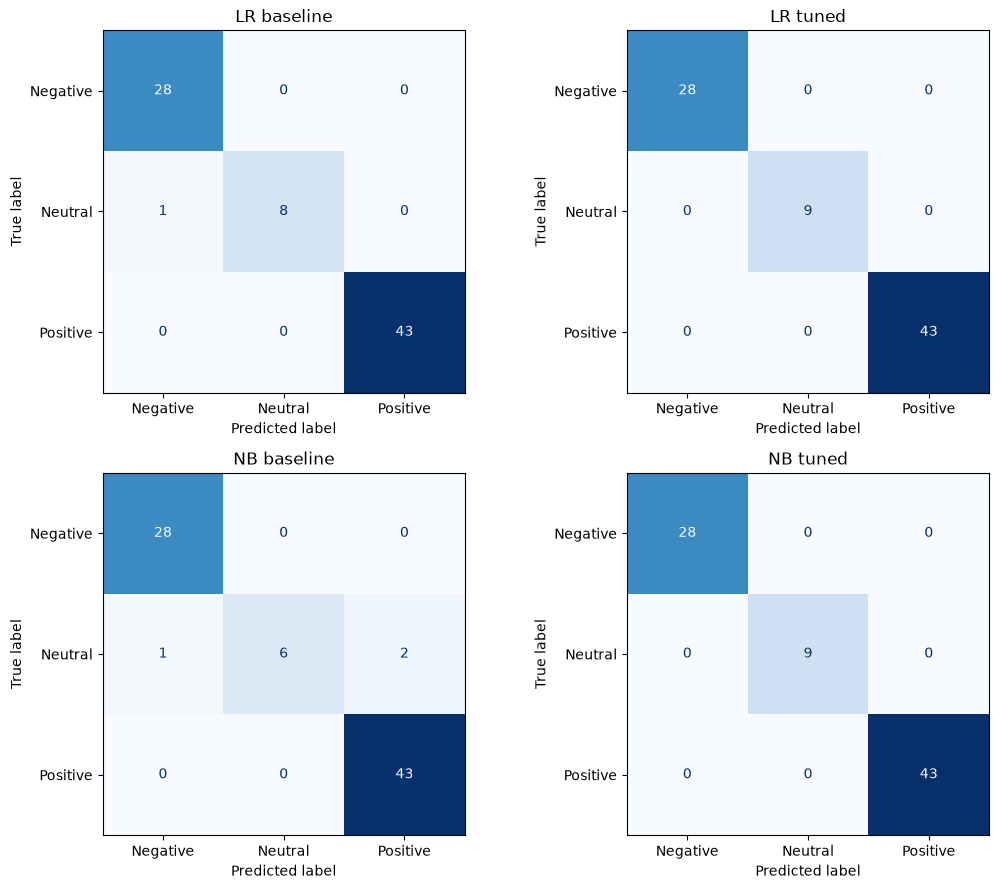

Change in LR macro F1 (tuned minus baseline): 0.0255
Change in NB macro F1 (tuned minus baseline): 0.0801


In [51]:
models={'LR baseline':base_lr,'LR tuned':lr_search.best_estimator_,
        'NB baseline':base_nb,'NB tuned':nb_search.best_estimator_}
rows=[];predictions={}
for name,model in models.items():
    pred=model.predict(X_test);predictions[name]=pred
    p,r,f,_=precision_recall_fscore_support(y_test,pred,average='macro',zero_division=0)
    fw=precision_recall_fscore_support(y_test,pred,average='weighted',zero_division=0)[2]
    rows.append({'Model':name,'Accuracy':accuracy_score(y_test,pred),'Macro precision':p,'Macro recall':r,'Macro F1':f,'Weighted F1':fw})
results=pd.DataFrame(rows).sort_values('Macro F1',ascending=False)
display(results.round(4))
for name in models:
    print('\n',name,'\n',classification_report(y_test,predictions[name],zero_division=0))
fig,axes=plt.subplots(2,2,figsize=(11,9))
for ax,(name,pred) in zip(axes.flat,predictions.items()):
    ConfusionMatrixDisplay.from_predictions(y_test,pred,labels=['Negative','Neutral','Positive'],ax=ax,cmap='Blues',colorbar=False)
    ax.set_title(name)
plt.tight_layout();plt.savefig(OUT/'05_confusion_matrices.png',dpi=160);plt.show()
results.to_csv(OUT/'model_comparison.csv',index=False)
print('Change in LR macro F1 (tuned minus baseline):',round(float(results.set_index('Model').loc['LR tuned','Macro F1']-results.set_index('Model').loc['LR baseline','Macro F1']),4))
print('Change in NB macro F1 (tuned minus baseline):',round(float(results.set_index('Model').loc['NB tuned','Macro F1']-results.set_index('Model').loc['NB baseline','Macro F1']),4))

Two models were selected, logistic regression and multinomial naive bayes. The 80 reviews dataset contains 43 positive , 28 negative and 9 neutral reviews. Logistic regression achieved the following results: 98,75% accuracy and 97,45% Macro F1 score, while multinomial naive bayes achieved 96.25% accuracy and 91.99% Macro F1 score. Both models demonstrate strong performance, they both accurately identified 100% of both negative and positive reviews, however, Logistic regression made one incorrect neutral review prediction and Multinomial naive bayes made three incorrect neutal reviews predictions. Logistic regression has therefore a higher neutral recall of 88,89% than Multinomial naive bayes at 66,67%.

The model's performance is then improved using GridSearchCV. Hyperparameter settings are set as follows: Logistic regression, C values of 0.1, 1, and 10. Naive bayes, alpha values of 0.1, 0.5 and 1.0. Both models improved post tuning, logistic regression went from accuracy of 98.78% to a 100%, Macro F1 results went from 97,45% to 100% as well. Naive bayes also went from accuracy of 96.25% to 100% and from Macro F1 of 91.99% to 100%. This indicates that hyperparameter tuning enabled both models to correctly classify all 80 test reviews including those they had initially misclassified.

In [53]:
best_name=results.iloc[0]['Model'];best_pred=predictions[best_name]
errors=pd.DataFrame({'ReviewText':X_test.values,'Actual':y_test.values,'Predicted':best_pred})
errors=errors[errors.Actual!=errors.Predicted]
print('Best test model:',best_name,'| Misclassifications:',len(errors));display(errors.head(10))

def repeated_ngrams(texts,n=5,top=10):
    counts=Counter()
    for text in texts:
        words=re.findall(r'\b[a-z]+\b',text.lower())
        counts.update(set(zip(*(words[i:] for i in range(n)))))
    return [(' '.join(k),v) for k,v in counts.most_common(top)]
print('Most repeated 5-word sequences across reviews:')
display(pd.DataFrame(repeated_ngrams(data.CleanText),columns=['phrase','number of reviews']))

Best test model: LR tuned | Misclassifications: 0


,ReviewText,Actual,Predicted


Most repeated 5-word sequences across reviews:


,phrase,number of reviews
0,this made the experience reassuring,54
1,overall this made the experience,54
2,made the experience reassuring and,54
3,the experience reassuring and straightforward,54
4,clear communication and timely assistance,54
5,appreciated the clear communication and,54
6,i appreciated the clear communication,54
7,the clear communication and timely,54
8,i expect when managing healthcare,54
9,support i expect when managing,54


Both models demonstrated high performance, however, logistic regression is most prefereable because even before tuning the model provided strong baseline results and it also provides feature coefficients that are interpretable. The company can use Naive Boyes as a comparison model to validate Logistic regression as they are both efficient.